In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
import pandas as pd

df = pd.read_csv(r"D:\Semester 5\NLP\modul-1\dataset_preprocessed.csv")
text_column = "processed_text"

df = df.dropna(subset=[text_column])

# Gunakan sample untuk eksperimen awal
sample = df[text_column].head(1000).astype(str).tolist()
print(f"Jumlah dokumen sample: {len(sample)}")

Jumlah dokumen sample: 1000


In [4]:
# Inisialisasi CountVectorizer
vectorizer_bow = CountVectorizer(max_features=5000)

# Fit dan transform
bow_matrix = vectorizer_bow.fit_transform(sample)

print("Shape matriks BoW:", bow_matrix.shape)
print("Jumlah vocabulary :", len(vectorizer_bow.vocabulary_))

Shape matriks BoW: (1000, 3218)
Jumlah vocabulary : 3218


In [5]:
vocab = vectorizer_bow.get_feature_names_out()
print("Contoh vocabulary:", vocab[:20])

Contoh vocabulary: ['abadi' 'abai' 'abang' 'abg' 'abis' 'abs' 'abu' 'acak' 'acapak' 'acara'
 'actual' 'ad' 'ada' 'adahdan' 'adakan' 'adam' 'adax' 'adil' 'adill' 'adu']


In [6]:
# Dokumen pertama dalam bentuk dense array
doc_vector = bow_matrix[0].toarray()[0]

# Tampilkan kata yang memiliki nilai > 0
nonzero_indices = np.where(doc_vector > 0)[0]
print("\nDokumen 1:")
print(sample[0])
print("\nRepresentasi BoW (kata dengan frekuensi > 0):")
for idx in nonzero_indices:
    print(f"  {vocab[idx]:<20} : {int(doc_vector[idx])}")


Dokumen 1:
bang kumis milik karakter salesman yg kuat ciri khas ulang unggul produk yg jual bukti gagal dng tanam dlm pikir masyarakat tuju angan persis contoh junjunganya

Representasi BoW (kata dengan frekuensi > 0):
  angan                : 1
  bang                 : 1
  bukti                : 1
  ciri                 : 1
  contoh               : 1
  dlm                  : 1
  dng                  : 1
  gagal                : 1
  jual                 : 1
  junjunganya          : 1
  karakter             : 1
  khas                 : 1
  kuat                 : 1
  kumis                : 1
  masyarakat           : 1
  milik                : 1
  persis               : 1
  pikir                : 1
  produk               : 1
  salesman             : 1
  tanam                : 1
  tuju                 : 1
  ulang                : 1
  unggul               : 1
  yg                   : 2


In [7]:
# Sparsity
total_elements = bow_matrix.shape[0] * bow_matrix.shape[1]
nonzero_elements = bow_matrix.nnz
sparsity = 1 - (nonzero_elements / total_elements)

print(f"Total elemen       : {total_elements:,}")
print(f"Elemen non-zero    : {nonzero_elements:,}")
print(f"Sparsity           : {sparsity:.4%}")

Total elemen       : 3,218,000
Elemen non-zero    : 10,469
Sparsity           : 99.6747%


In [8]:
# Inisialisasi TfidfVectorizer
vectorizer_tfidf = TfidfVectorizer(max_features=5000)

# Fit dan transform
tfidf_matrix = vectorizer_tfidf.fit_transform(sample)

print("Shape matriks TF-IDF:", tfidf_matrix.shape)

Shape matriks TF-IDF: (1000, 3218)


In [9]:
def top_tfidf_words(doc_index, tfidf_mat, feature_names, top_n=10):
    doc_vector = tfidf_mat[doc_index].toarray()[0]
    top_indices = doc_vector.argsort()[::-1][:top_n]
    return [(feature_names[i], doc_vector[i]) for i in top_indices if doc_vector[i] > 0]

feature_names = vectorizer_tfidf.get_feature_names_out()

print("Top 10 kata TF-IDF Dokumen 0:")
print(sample[0][:150])
print()
for word, score in top_tfidf_words(0, tfidf_matrix, feature_names):
    print(f"  {word:<20} : {score:.4f}")

Top 10 kata TF-IDF Dokumen 0:
bang kumis milik karakter salesman yg kuat ciri khas ulang unggul produk yg jual bukti gagal dng tanam dlm pikir masyarakat tuju angan persis contoh j

  persis               : 0.2403
  khas                 : 0.2403
  junjunganya          : 0.2403
  angan                : 0.2403
  produk               : 0.2268
  salesman             : 0.2268
  tanam                : 0.2268
  karakter             : 0.2268
  ciri                 : 0.2268
  unggul               : 0.2172


In [10]:
# Ambil 5 dokumen pertama
subset = tfidf_matrix[:5]

# Hitung cosine similarity
sim_matrix = cosine_similarity(subset)

print("Cosine Similarity Matrix (5 dokumen):")
print(np.round(sim_matrix, 3))


Cosine Similarity Matrix (5 dokumen):
[[1.    0.042 0.031 0.    0.054]
 [0.042 1.    0.    0.    0.   ]
 [0.031 0.    1.    0.    0.008]
 [0.    0.    0.    1.    0.039]
 [0.054 0.    0.008 0.039 1.   ]]


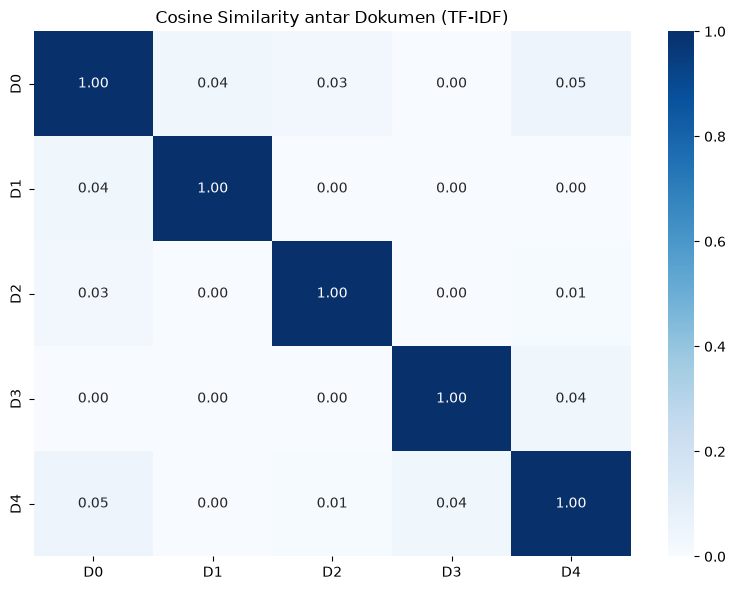

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    sim_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=[f"D{i}" for i in range(5)],
    yticklabels=[f"D{i}" for i in range(5)]
)
plt.title("Cosine Similarity antar Dokumen (TF-IDF)")
plt.tight_layout()
plt.show()

In [12]:
def search_documents(query, vectorizer, tfidf_mat, docs, top_n=5):
    query_vec = vectorizer.transform([query])
    similarities = cosine_similarity(query_vec, tfidf_mat)[0]
    top_indices = similarities.argsort()[::-1][:top_n]
    results = []
    for idx in top_indices:
        results.append({
            "index": idx,
            "similarity": similarities[idx],
            "text": docs[idx][:100]
        })
    return results

# Contoh
query = "produk bagus kualitas"
results = search_documents(query, vectorizer_tfidf, tfidf_matrix, sample)

print(f"Query: '{query}'")
print("=" * 60)
for i, res in enumerate(results, 1):
    print(f"{i}. [Score: {res['similarity']:.4f}]")
    print(f"   {res['text']}...")
    print()

Query: 'produk bagus kualitas'
1. [Score: 0.2897]
   program bagus iklan nya...

2. [Score: 0.2514]
   mbg jangka cipta sdm yg kualitas sblm mbg sdm nya tdk kualitas bgtu mksdnya...

3. [Score: 0.2264]
   mbg ajang cari untung dapur tdk kualitas...

4. [Score: 0.1836]
   acara cnn gak bagus banyak potong jelas org...

5. [Score: 0.1787]
   efektif efesiensi kualitas laksana program mbg baik dana transfer langsung orang siswa awas tinggal ...



In [13]:
print("=" * 50)
print("PERBANDINGAN BOW vs TF-IDF")
print("=" * 50)

# Ambil 1 dokumen
doc_idx = 0
bow_vec = vectorizer_bow.transform([sample[doc_idx]]).toarray()[0]
tfidf_vec = vectorizer_tfidf.transform([sample[doc_idx]]).toarray()[0]

bow_vocab = vectorizer_bow.get_feature_names_out()
tfidf_vocab = vectorizer_tfidf.get_feature_names_out()

print(f"\nDokumen: {sample[doc_idx][:100]}...")
print("\nTop 10 Kata — BoW (frekuensi):")
top_bow = sorted(
    [(bow_vocab[i], bow_vec[i]) for i in range(len(bow_vec)) if bow_vec[i] > 0],
    key=lambda x: x[1], reverse=True
)[:10]
for word, val in top_bow:
    print(f"  {word:<20} : {int(val)}")

print("\nTop 10 Kata — TF-IDF (bobot):")
for word, score in top_tfidf_words(doc_idx, tfidf_matrix, tfidf_vocab):
    print(f"  {word:<20} : {score:.4f}")

PERBANDINGAN BOW vs TF-IDF

Dokumen: bang kumis milik karakter salesman yg kuat ciri khas ulang unggul produk yg jual bukti gagal dng tan...

Top 10 Kata — BoW (frekuensi):
  yg                   : 2
  angan                : 1
  bang                 : 1
  bukti                : 1
  ciri                 : 1
  contoh               : 1
  dlm                  : 1
  dng                  : 1
  gagal                : 1
  jual                 : 1

Top 10 Kata — TF-IDF (bobot):
  persis               : 0.2403
  khas                 : 0.2403
  junjunganya          : 0.2403
  angan                : 0.2403
  produk               : 0.2268
  salesman             : 0.2268
  tanam                : 0.2268
  karakter             : 0.2268
  ciri                 : 0.2268
  unggul               : 0.2172


In [5]:
# ANALISIS TUGAS PERTEMUAN 6
# Sel ini menyiapkan dependensinya sendiri, jadi dapat dijalankan mandiri.
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

df = pd.read_csv(r"D:\Semester 5\NLP\modul-1\dataset_preprocessed.csv")
df = df.dropna(subset=["processed_text"]).reset_index(drop=True)
sample = df["processed_text"].head(1000).astype(str).tolist()

vectorizer_bow = CountVectorizer(max_features=5000)
bow_matrix = vectorizer_bow.fit_transform(sample)
vectorizer_tfidf = TfidfVectorizer(max_features=5000)
tfidf_matrix = vectorizer_tfidf.fit_transform(sample)

# 1. Cosine similarity pada tiga dokumen pilihan
selected_docs = [193, 702, 553]
selected_tfidf = tfidf_matrix[selected_docs]
selected_similarity = cosine_similarity(selected_tfidf)

print("1. COSINE SIMILARITY TIGA DOKUMEN")
for row, doc_i in enumerate(selected_docs):
    print(f"\nDokumen {doc_i}: {df.iloc[doc_i]['text_original']}")
    for col in range(row + 1, len(selected_docs)):
        doc_j = selected_docs[col]
        print(
            f"Similarity dokumen {doc_i} dan {doc_j}: "
            f"{selected_similarity[row, col]:.4f}"
        )

pair_scores = [
    (selected_similarity[i, j], selected_docs[i], selected_docs[j])
    for i in range(len(selected_docs))
    for j in range(i + 1, len(selected_docs))
]
best_score, best_doc_i, best_doc_j = max(pair_scores)
print(
    f"\nPasangan paling mirip: dokumen {best_doc_i} dan {best_doc_j} "
    f"(similarity {best_score:.4f})"
)

1. COSINE SIMILARITY TIGA DOKUMEN

Dokumen 193: Anak Bangsa tidak butuh makan Gratis, tapi pendidikan gratis lebih penting
Similarity dokumen 193 dan 702: 0.3918
Similarity dokumen 193 dan 553: 0.4286

Dokumen 702: MAKAN GRATIS??? ITU UANG RAKYAT.. negara itu wajib, bukan program
Similarity dokumen 702 dan 553: 0.3542

Dokumen 553: wong rakyatnya pengenya sekolah gratis kok malah di kasih makan gratis, kepie cara brfikire pemerintah

Pasangan paling mirip: dokumen 193 dan 553 (similarity 0.4286)


In [8]:
# 4. Ukur sparsity dan perkirakan kebutuhan memori sparse vs dense.
total_elements = bow_matrix.shape[0] * bow_matrix.shape[1]
nonzero_elements = bow_matrix.nnz
sparsity = 1 - (nonzero_elements / total_elements)
sparse_bytes = (
    bow_matrix.data.nbytes
    + bow_matrix.indices.nbytes
    + bow_matrix.indptr.nbytes
)
dense_bytes = bow_matrix.shape[0] * bow_matrix.shape[1] * np.dtype(np.int64).itemsize

print("\n4. DAMPAK SPARSITY")
print(f"Ukuran matriks BoW: {bow_matrix.shape}")
print(f"Elemen bukan nol: {nonzero_elements:,} dari {total_elements:,}")
print(f"Sparsity: {sparsity:.4%}")
print(f"Perkiraan ukuran format sparse CSR: {sparse_bytes:,} byte")
print(f"Perkiraan ukuran format dense int64: {dense_bytes:,} byte")
print(
    "Sparsity tinggi menghemat memori dan komputasi jika nilai nol "
    "dilewati oleh operasi sparse. Format sparse memiliki overhead indeks, "
    "jadi manfaatnya bergantung pada ukuran dan tingkat sparsity matriks."
)


4. DAMPAK SPARSITY
Ukuran matriks BoW: (1000, 3218)
Elemen bukan nol: 10,469 dari 3,218,000
Sparsity: 99.6747%
Perkiraan ukuran format sparse CSR: 129,632 byte
Perkiraan ukuran format dense int64: 25,744,000 byte
Sparsity tinggi menghemat memori dan komputasi jika nilai nol dilewati oleh operasi sparse. Format sparse memiliki overhead indeks, jadi manfaatnya bergantung pada ukuran dan tingkat sparsity matriks.


In [7]:
# 3. Bandingkan frekuensi BoW dengan bobot TF-IDF pada dokumen yang sama.
# BoW dinormalisasi L2 supaya skalanya dapat dibandingkan dengan TF-IDF.
comparison_doc = 0
bow_vector = vectorizer_bow.transform([sample[comparison_doc]]).toarray()[0]
bow_norm = bow_vector / np.linalg.norm(bow_vector)
tfidf_vector = vectorizer_tfidf.transform([sample[comparison_doc]]).toarray()[0]
bow_terms = vectorizer_bow.get_feature_names_out()
tfidf_terms = vectorizer_tfidf.get_feature_names_out()
tfidf_term_to_index = {term: i for i, term in enumerate(tfidf_terms)}

comparison = []
for i, term in enumerate(bow_terms):
    if bow_vector[i] > 0 and term in tfidf_term_to_index:
        tfidf_score = tfidf_vector[tfidf_term_to_index[term]]
        comparison.append(
            (abs(tfidf_score - bow_norm[i]), term, bow_vector[i], bow_norm[i], tfidf_score)
        )

comparison.sort(reverse=True)
print(f"\n3. PERUBAHAN SKOR BoW vs TF-IDF - Dokumen {comparison_doc}")
print("Kata                 BoW   BoW-normalisasi   TF-IDF    Selisih")
for difference, term, bow_count, bow_score, tfidf_score in comparison[:10]:
    print(
        f"{term:<20} {bow_count:>4.0f} {bow_score:>15.4f} "
        f"{tfidf_score:>9.4f} {difference:>10.4f}"
    )
if comparison:
    difference, term, bow_count, bow_score, tfidf_score = comparison[0]
    print(
        f"Perubahan absolut terbesar: '{term}' "
        f"(BoW-normalisasi {bow_score:.4f} menjadi TF-IDF {tfidf_score:.4f})."
    )


3. PERUBAHAN SKOR BoW vs TF-IDF - Dokumen 0
Kata                 BoW   BoW-normalisasi   TF-IDF    Selisih
yg                      2          0.3780    0.1655     0.2125
kumis                   1          0.1890    0.1214     0.0675
masyarakat              1          0.1890    0.1312     0.0578
persis                  1          0.1890    0.2403     0.0513
khas                    1          0.1890    0.2403     0.0513
junjunganya             1          0.1890    0.2403     0.0513
angan                   1          0.1890    0.2403     0.0513
bang                    1          0.1890    0.1389     0.0501
tuju                    1          0.1890    0.1490     0.0399
tanam                   1          0.1890    0.2268     0.0378
Perubahan absolut terbesar: 'yg' (BoW-normalisasi 0.3780 menjadi TF-IDF 0.1655).


In [6]:
# 2. Retrieval dengan query baru
query_baru = "anak makan gratis"
query_vector = vectorizer_tfidf.transform([query_baru])
query_scores = cosine_similarity(query_vector, tfidf_matrix).ravel()
top_indices = query_scores.argsort()[::-1][:5]

print(f"\n2. DOCUMENT RETRIEVAL - Query: '{query_baru}'")
for rank, doc_index in enumerate(top_indices, start=1):
    original_text = df.iloc[doc_index]["text_original"]
    print(
        f"{rank}. Dokumen {doc_index} | skor {query_scores[doc_index]:.4f}\n"
        f"   {original_text[:250]}"
    )
print(
    "Relevansi: periksa hasil di atas; hasil yang membahas anak dan makan "
    "gratis relevan dengan query. Skor menunjukkan kemiripan teks, bukan "
    "penilaian relevansi manusia."
)


2. DOCUMENT RETRIEVAL - Query: 'anak makan gratis'
1. Dokumen 193 | skor 0.7469
   Anak Bangsa tidak butuh makan Gratis, tapi pendidikan gratis lebih penting
2. Dokumen 553 | skor 0.4744
   wong rakyatnya pengenya sekolah gratis kok malah di kasih makan gratis, kepie cara brfikire pemerintah
3. Dokumen 297 | skor 0.4703
   Anak anak di kasih gratisan ya seneng,tapi orang tua masih banyak pembangunan yang lebih penting khususnya  pendidikan gratis bagi SMA SMK, sekolah negri di perbanyak
4. Dokumen 702 | skor 0.4697
   MAKAN GRATIS??? ITU UANG RAKYAT.. negara itu wajib, bukan program
5. Dokumen 354 | skor 0.4246
   Hentikan mbg, karena juga banyak anak anak gak mau makan sehingga di ambil gurunya
Relevansi: periksa hasil di atas; hasil yang membahas anak dan makan gratis relevan dengan query. Skor menunjukkan kemiripan teks, bukan penilaian relevansi manusia.
